# Building Perceptron

Ce notebook regroupe tout mon travail sur le projet Building Perceptron. Le but est de comprendre comment fonctionne le perceptron de Rosenblatt, de le coder moi-même en Python, puis de l'utiliser sur un vrai jeu de données médicales : le Breast Cancer Wisconsin, où il faut prédire si une tumeur est maligne ou bénigne.

Le notebook suit l'ordre du sujet :

1. Machine Learning et Deep Learning
2. Le perceptron (réponses aux questions 1 à 6)
3. Mon perceptron en Python et le test sur des données aléatoires (question 7)
4. Chargement et nettoyage des données Breast Cancer Wisconsin
5. Analyse exploratoire
6. Réduction de dimension avec une ACP
7. Modélisation et évaluation
8. Conclusion et pistes d'amélioration

In [1]:
import sys
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)

# perceptron.py est à la racine du projet, un dossier au-dessus du notebook
sys.path.insert(0, str(pathlib.Path().resolve().parent))
from perceptron import Perceptron

DATA_PATH = "../data/bcw_data.csv"

## 1. Machine Learning et Deep Learning

### Définitions

Le **Machine Learning** (apprentissage automatique), c'est une branche de l'intelligence artificielle où on ne donne pas des règles à l'ordinateur : on lui donne des exemples, et l'algorithme trouve tout seul les règles à partir des données. Par exemple, au lieu d'écrire "si la tumeur fait plus de X mm alors elle est maligne", on lui montre des centaines de tumeurs déjà diagnostiquées et il apprend la frontière lui-même. Des exemples d'algorithmes : la régression linéaire ou logistique, les arbres de décision, les forêts aléatoires, les SVM, les k plus proches voisins.

Le **Deep Learning** (apprentissage profond) est une sous-partie du Machine Learning. Il utilise des réseaux de neurones artificiels avec beaucoup de couches empilées (d'où le mot "profond"). Chaque couche transforme les données et le réseau apprend lui-même quelles caractéristiques sont utiles, directement à partir des données brutes (les pixels d'une image, les mots d'un texte, etc.).

### Comparaison

| | Machine Learning "classique" | Deep Learning |
|---|---|---|
| Données | Plutôt tabulaires (tableaux de colonnes) | Plutôt non structurées : images, texte, son |
| Quantité de données | Fonctionne avec quelques centaines ou milliers de lignes | A besoin de beaucoup de données |
| Choix des variables | Souvent fait à la main (feature engineering) | Le réseau apprend lui-même les représentations |
| Puissance de calcul | Un ordinateur classique suffit | Souvent besoin de GPU |
| Interprétabilité | Plus facile à expliquer | Plutôt une "boîte noire" |

### Quand utiliser l'un ou l'autre ?

Si les données sont un tableau avec peu de lignes, ou si on a besoin d'expliquer les décisions du modèle (ce qui est souvent le cas en santé), le Machine Learning classique est plus adapté. Le Deep Learning devient intéressant quand on a énormément de données non structurées, comme des images ou du texte, et assez de puissance de calcul pour entraîner un gros réseau.

C'est d'ailleurs notre cas dans ce projet : le dataset Breast Cancer Wisconsin est un tableau de 569 lignes, ce qui est beaucoup trop petit pour du Deep Learning. Par contre le perceptron est intéressant à étudier parce que c'est la brique de base de tous les réseaux de neurones.

### Trois applications du Deep Learning

**L'imagerie médicale.** Des réseaux de neurones convolutifs (CNN) sont entraînés sur des milliers de radios, de mammographies ou de photos de grains de beauté pour repérer des tumeurs ou des lésions suspectes. Ils servent d'aide au diagnostic pour les médecins. Ça rejoint directement le sujet de ce projet.

**Les modèles de langage.** Les modèles GPT d'OpenAI (utilisés dans ChatGPT) sont des réseaux de neurones très profonds entraînés sur d'énormes quantités de texte. Ils peuvent répondre à des questions, résumer, traduire ou écrire du code.

**Quick, Draw! (Google AI Experiments).** C'est un jeu en ligne où on dessine un objet et un réseau de neurones essaie de deviner ce que c'est en temps réel. Le modèle a appris à partir de millions de dessins faits par les joueurs. C'est un bon exemple de reconnaissance d'images à partir de données brutes.

## 2. Le perceptron

### Q1. Qu'est-ce qu'un perceptron ? Quel lien avec un neurone biologique ?

Le perceptron est le premier modèle de neurone artificiel capable d'apprendre. Il a été inventé par Frank Rosenblatt en 1957, en s'inspirant du neurone formel de McCulloch et Pitts (1943). C'est un algorithme de **classification binaire** : il reçoit plusieurs valeurs en entrée et il répond 0 ou 1.

Il imite (de façon très simplifiée) un neurone biologique :

| Neurone biologique | Perceptron |
|---|---|
| Les dendrites reçoivent les signaux des autres neurones | Les entrées $x_1, ..., x_n$ |
| Les synapses sont plus ou moins fortes | Les poids $w_1, ..., w_n$ |
| Le corps cellulaire additionne les signaux reçus | La somme pondérée $\sum w_i x_i + b$ |
| Le neurone "s'active" seulement si un seuil est dépassé | La fonction d'activation (seuil) |
| L'axone transmet le signal (ou non) | La sortie $\hat{y}$ = 0 ou 1 |

### Q2. La fonction mathématique du perceptron

Le perceptron calcule d'abord une somme pondérée de ses entrées :

$$z = \sum_{i=1}^{n} w_i x_i + b = w \cdot x + b$$

puis il applique une fonction seuil pour obtenir la prédiction :

$$\hat{y} = f(z) = \begin{cases} 1 & \text{si } z \geq 0 \\ 0 & \text{si } z < 0 \end{cases}$$

Les termes de l'équation :

- $x_i$ : les valeurs des variables d'entrée (par exemple le rayon ou la texture d'une cellule)
- $w_i$ : les poids, qui disent à quel point chaque entrée compte dans la décision. Ce sont eux que le modèle apprend.
- $b$ : le biais, qui permet de décaler le seuil de décision (sans lui, la frontière passerait forcément par l'origine)
- $z$ : le résultat de la somme pondérée
- $f$ : la fonction d'activation
- $\hat{y}$ : la classe prédite

Son usage : séparer deux classes. L'équation $w \cdot x + b = 0$ correspond à une droite en 2D (un hyperplan en dimension plus grande). Tous les points d'un côté sont classés 1, ceux de l'autre côté sont classés 0. Le perceptron est donc un **classifieur linéaire**.

### Q3. Règles d'apprentissage

**La règle du perceptron (Rosenblatt).** Après chaque exemple, on compare la prédiction $\hat{y}$ à la vraie classe $y$ et on corrige les poids :

$$w_i \leftarrow w_i + \eta \,(y - \hat{y})\, x_i \qquad b \leftarrow b + \eta \,(y - \hat{y})$$

où $\eta$ est le taux d'apprentissage (learning rate). Si la prédiction est bonne, $y - \hat{y} = 0$ et rien ne change. Si le modèle a prédit 0 au lieu de 1, on ajoute $\eta x$ aux poids pour augmenter $z$ la prochaine fois, et l'inverse s'il a prédit 1 au lieu de 0.

**La règle de Hebb.** C'est la plus ancienne idée : "des neurones qui s'activent ensemble renforcent leur connexion". Le poids augmente quand l'entrée et la sortie sont actives en même temps : $w_i \leftarrow w_i + \eta \, x_i \, y$.

**La règle delta (Widrow-Hoff, utilisée par ADALINE).** Elle ressemble à la règle du perceptron, mais l'erreur est calculée sur la sortie continue $z$ au lieu de la sortie 0/1. On minimise l'erreur quadratique par **descente de gradient** : $w_i \leftarrow w_i + \eta\,(y - z)\,x_i$. C'est cette idée de gradient qui est utilisée ensuite pour entraîner les réseaux de neurones modernes.

### Q4. La fonction d'activation

Le perceptron utilise la **fonction de Heaviside** (fonction marche ou seuil) : elle renvoie 1 si $z \geq 0$ et 0 sinon. Une variante est la fonction signe, qui renvoie +1 ou -1.

Dans les réseaux de neurones actuels, on la remplace par des fonctions dérivables comme la sigmoïde ou la ReLU, parce que la fonction seuil n'a pas de dérivée utilisable et empêche donc d'utiliser la descente de gradient sur plusieurs couches.

### Q5. Le processus d'entraînement

1. On initialise les poids et le biais (à 0 ou à de petites valeurs aléatoires).
2. Pour chaque exemple du jeu d'entraînement :
    - on calcule $z = w \cdot x + b$,
    - on applique la fonction seuil pour obtenir $\hat{y}$,
    - on compare avec la vraie classe $y$,
    - si c'est faux, on met à jour les poids et le biais avec la règle du perceptron.
3. Un passage complet sur toutes les données s'appelle une **époque**. On recommence pendant plusieurs époques.
4. On s'arrête quand il n'y a plus d'erreur, ou quand on a atteint le nombre maximum d'époques.

Rosenblatt a montré que si les données sont linéairement séparables, cet algorithme trouve une frontière qui sépare parfaitement les classes en un nombre fini d'étapes (théorème de convergence du perceptron).

### Q6. Les limites du perceptron

- **Il ne sait séparer que des données linéairement séparables.** L'exemple le plus connu est le XOR : aucune droite ne peut séparer les deux classes. Minsky et Papert l'ont montré en 1969 et ça a beaucoup ralenti la recherche sur les réseaux de neurones à l'époque.
- **Si les données ne sont pas séparables, il ne converge jamais.** Les poids continuent de bouger à chaque époque et le résultat final dépend de l'époque où on s'arrête.
- **La sortie est seulement 0 ou 1.** Il ne donne pas de probabilité, donc on ne sait pas si le modèle est "sûr" de sa réponse.
- **Il est sensible à l'échelle des variables** (il faut standardiser) et à l'ordre dans lequel on lui présente les exemples.
- **Une seule couche** : il ne peut pas apprendre de relations complexes. Pour ça il faut empiler des neurones en plusieurs couches (perceptron multicouche).

## 3. Mon perceptron en Python (Q7)

J'ai codé le perceptron sous forme de classe dans le fichier `perceptron.py`. Elle contient :

- `__init__` : on choisit le taux d'apprentissage et le nombre d'époques. Les poids `W` et le biais `b` sont créés pendant l'entraînement.
- `_activation` : la fonction de Heaviside, avec `np.where(z >= 0, 1, 0)`.
- `fit` : la boucle d'entraînement. Les poids partent de 0 puis sont corrigés à chaque erreur avec la règle du perceptron. Le nombre d'erreurs de chaque époque est gardé dans `errors_` pour pouvoir tracer la courbe d'apprentissage.
- `predict` : calcule $z = X \cdot W + b$ puis applique le seuil.
- `plot` : affiche les points et la frontière de décision, uniquement quand il y a 2 variables.

### Test sur des données aléatoires séparables

Pour vérifier que mon perceptron fonctionne, je génère deux nuages de points aléatoires en 2D : la classe 0 autour de (-2, -2) et la classe 1 autour de (2, 2). Ils sont assez éloignés pour qu'une droite puisse les séparer.

In [2]:
rng = np.random.default_rng(42)
n = 100

classe_0 = rng.normal(loc=-2, scale=1, size=(n, 2))
classe_1 = rng.normal(loc=2, scale=1, size=(n, 2))

X_fake = np.vstack([classe_0, classe_1])
y_fake = np.array([0] * n + [1] * n)

X_fake_train, X_fake_test, y_fake_train, y_fake_test = train_test_split(
    X_fake, y_fake, test_size=0.2, random_state=42, stratify=y_fake
)

p_fake = Perceptron(learning_rate=0.1, n_epochs=20)
p_fake.fit(X_fake_train, y_fake_train)

print("Poids :", p_fake.W, "| biais :", p_fake.b)
print("Accuracy sur le test :", accuracy_score(y_fake_test, p_fake.predict(X_fake_test)))

Poids : [0.39370207 0.20525791] | biais : -0.2
Accuracy sur le test : 1.0


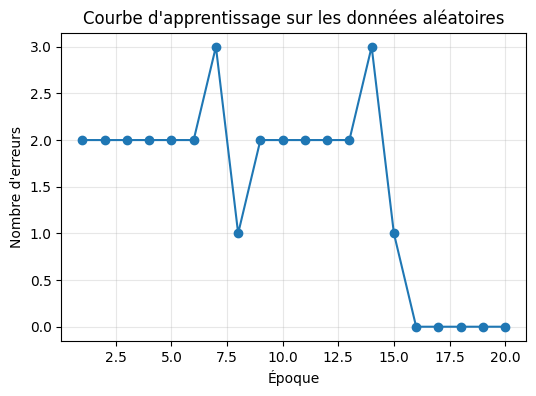

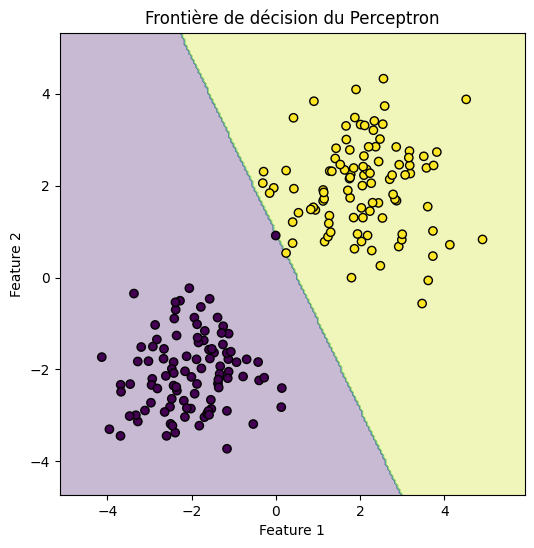

In [3]:
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(p_fake.errors_) + 1), p_fake.errors_, marker="o")
plt.xlabel("Époque")
plt.ylabel("Nombre d'erreurs")
plt.title("Courbe d'apprentissage sur les données aléatoires")
plt.grid(alpha=0.3)
plt.show()

p_fake.plot(X_fake, y_fake)

Le nombre d'erreurs hésite un peu au début (entre 1 et 3 erreurs), puis tombe à 0 à partir de la 16e époque et n'en bouge plus : le perceptron a trouvé une droite qui sépare parfaitement les deux nuages, et elle se voit bien sur le deuxième graphique. Ça confirme le théorème de convergence : quand les données sont linéairement séparables, l'algorithme finit toujours par converger. Mon implémentation fonctionne.

### Test sur le XOR (données non séparables)

Pour illustrer la principale limite du perceptron, je le teste aussi sur le problème du XOR. La sortie vaut 1 seulement quand une des deux entrées vaut 1, mais pas les deux.

Erreurs sur les 10 dernières époques : [4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
Prédictions : [1 1 0 0] | vraies classes : [0 1 1 0]
Accuracy : 0.5


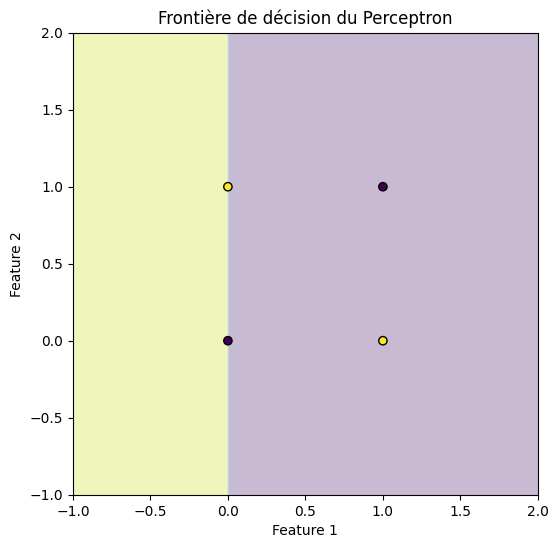

In [4]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])

p_xor = Perceptron(learning_rate=0.1, n_epochs=50)
p_xor.fit(X_xor, y_xor)

print("Erreurs sur les 10 dernières époques :", p_xor.errors_[-10:])
print("Prédictions :", p_xor.predict(X_xor), "| vraies classes :", y_xor)
print("Accuracy :", accuracy_score(y_xor, p_xor.predict(X_xor)))

p_xor.plot(X_xor, y_xor)

Ici les erreurs ne tombent jamais à 0, même après 50 époques : les poids tournent en rond. Il n'existe aucune droite qui met (0,1) et (1,0) d'un côté et (0,0) et (1,1) de l'autre, donc le perceptron ne peut pas réussir. C'est exactement la limite vue dans la question 6.

Une remarque que j'ai faite en testant : comme mes poids partent de 0, changer le taux d'apprentissage ne change pas les prédictions. Les poids et le biais sont juste multipliés par le même nombre, donc la frontière reste au même endroit. Le learning rate a un vrai effet seulement quand les poids sont initialisés au hasard.

## 4. Breast Cancer Wisconsin : chargement et nettoyage

Le dataset contient 569 tumeurs du sein. Pour chaque tumeur, une image d'une ponction à l'aiguille fine a été numérisée et 10 caractéristiques ont été mesurées sur les noyaux des cellules :

- **radius** : moyenne des distances entre le centre et les points du contour
- **texture** : écart-type des niveaux de gris
- **perimeter** : périmètre
- **area** : aire
- **smoothness** : variation locale de la longueur des rayons
- **compactness** : périmètre² / aire - 1
- **concavity** : profondeur des parties concaves du contour
- **concave points** : nombre de parties concaves du contour
- **symmetry** : symétrie
- **fractal dimension** : "approximation de la côte" - 1

Chaque caractéristique est donnée 3 fois : la moyenne (`_mean`), l'erreur standard (`_se`) et la "pire" valeur, c'est-à-dire la moyenne des 3 plus grandes (`_worst`). Ça fait 30 variables. Il y a aussi un identifiant (`id`) et le diagnostic (`diagnosis`) : M pour maligne, B pour bénigne.

In [5]:
df = pd.read_csv(DATA_PATH)
print("Dimensions :", df.shape)
df.head()

Dimensions : (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842303,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,842304,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,842305,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,842306,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

Toutes les variables sont numériques sauf `diagnosis`. Il y a une 33e colonne `Unnamed: 32` qui n'est pas dans la description du dataset. Je regarde ce qu'elle contient :

In [7]:
print("Valeurs uniques de 'Unnamed: 32' :", df["Unnamed: 32"].unique())

Valeurs uniques de 'Unnamed: 32' : [nan]


Elle est complètement vide : elle vient sûrement d'une virgule en trop à la fin de chaque ligne du fichier CSV. Je la supprime. Je supprime aussi `id`, qui sert juste à identifier les patientes et n'apporte aucune information pour prédire le diagnostic.

Ensuite je transforme `diagnosis` en variable numérique `target` : 1 pour maligne, 0 pour bénigne. Je mets la classe maligne à 1 parce que c'est elle qu'on cherche à détecter.

In [8]:
df = df.drop(columns=["Unnamed: 32", "id"])

df["target"] = df["diagnosis"].map({"M": 1, "B": 0})
df = df.drop(columns=["diagnosis"])

print("Dimensions après nettoyage :", df.shape)
print("Valeurs manquantes :", df.isna().sum().sum())
print("Doublons :", df.duplicated().sum())

Dimensions après nettoyage : (569, 31)
Valeurs manquantes : 0
Doublons : 0


Après nettoyage il reste 569 lignes et 31 colonnes (30 variables + la cible). Il n'y a aucune valeur manquante et aucun doublon, donc pas besoin d'imputation. Le dataset est déjà assez propre.

## 5. Analyse exploratoire

### Répartition des classes

target
0    357
1    212
Name: count, dtype: int64
target
0    62.7
1    37.3
Name: count, dtype: float64


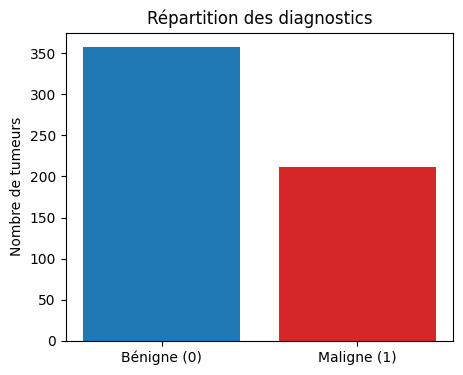

In [9]:
counts = df["target"].value_counts().sort_index()
print(counts)
print((counts / len(df) * 100).round(1))

plt.figure(figsize=(5, 4))
plt.bar(["Bénigne (0)", "Maligne (1)"], counts.values, color=["tab:blue", "tab:red"])
plt.ylabel("Nombre de tumeurs")
plt.title("Répartition des diagnostics")
plt.show()

Il y a 357 tumeurs bénignes (63 %) et 212 malignes (37 %). Les classes sont un peu déséquilibrées, mais pas énormément. Ça veut quand même dire que l'accuracy seule ne suffira pas pour évaluer le modèle : un modèle qui répond toujours "bénigne" aurait déjà 63 % d'accuracy. Il faudra surtout regarder le **rappel** (recall) sur la classe maligne, parce que rater un cancer est beaucoup plus grave que l'inverse.

### Statistiques descriptives

In [10]:
df.describe().T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
radius_mean,14.127,3.524,6.981,28.110
texture_mean,19.290,4.301,9.710,39.280
perimeter_mean,91.969,24.299,43.790,188.500
area_mean,654.889,351.914,143.500,2501.000
smoothness_mean,0.096,0.014,0.053,0.163
compactness_mean,0.104,0.053,0.019,0.345
concavity_mean,0.089,0.080,0.000,0.427
concave points_mean,0.049,0.039,0.000,0.201
symmetry_mean,0.181,0.027,0.106,0.304
fractal_dimension_mean,0.063,0.007,0.050,0.097


Les variables ont des échelles complètement différentes : `area_mean` va de 143 à 2501 alors que `smoothness_mean` reste autour de 0,1. Le perceptron fait une somme pondérée, donc sans mise à l'échelle les variables avec de grandes valeurs (comme l'aire) écraseraient les autres. Il faudra **standardiser** les données avant l'entraînement.

### Distribution des variables selon le diagnostic

Je regarde les 10 variables `_mean` en séparant les tumeurs bénignes et malignes.

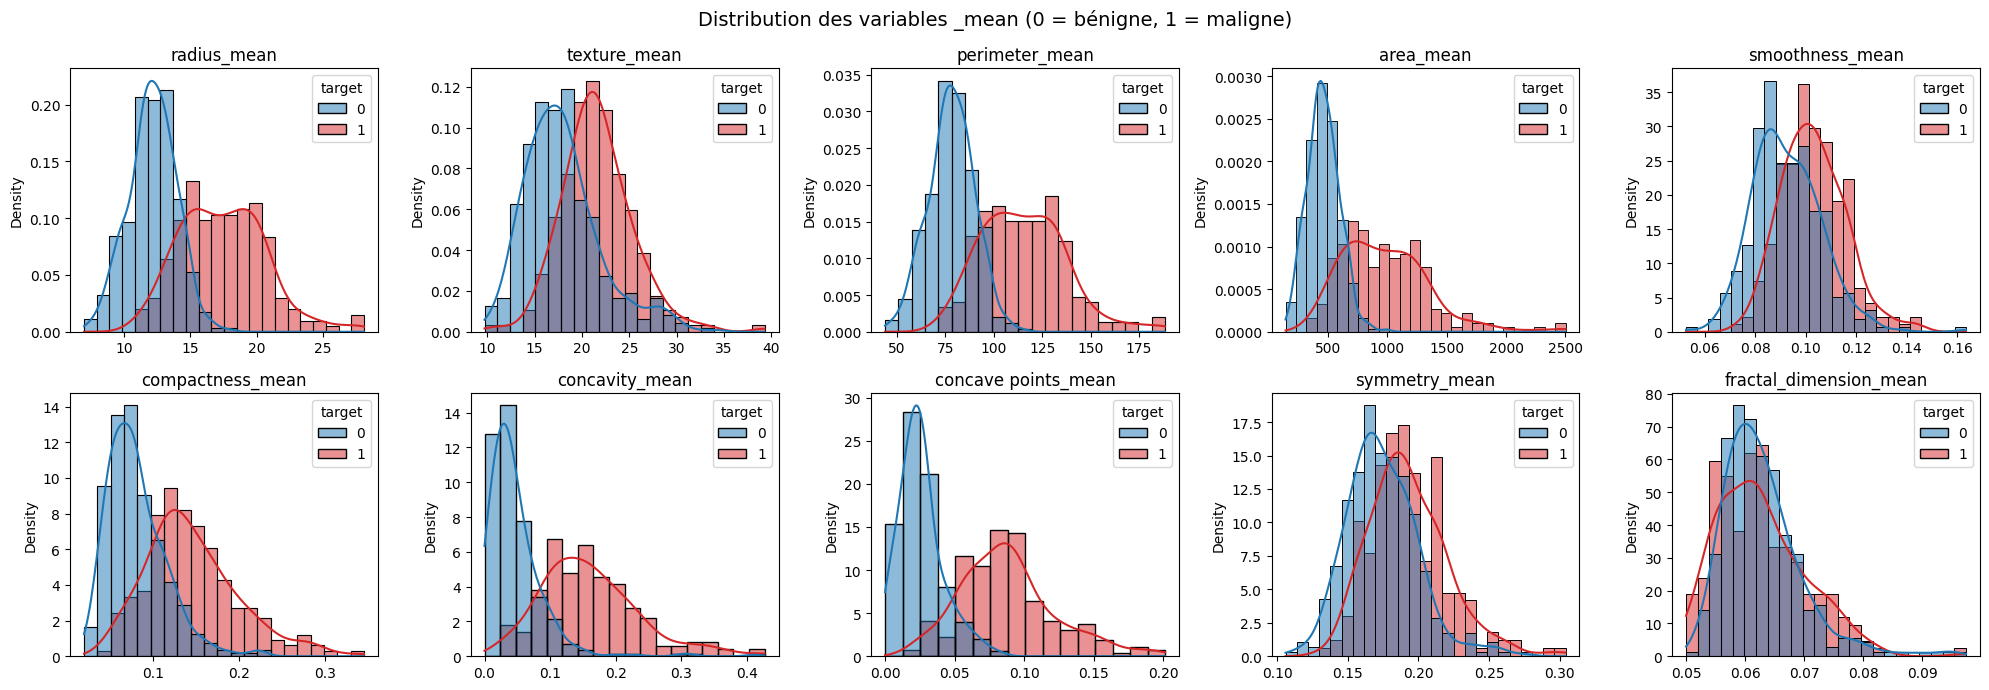

In [11]:
mean_cols = [c for c in df.columns if c.endswith("_mean")]

fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(axes.ravel(), mean_cols):
    sns.histplot(data=df, x=col, hue="target", kde=True, ax=ax,
                 palette={0: "tab:blue", 1: "tab:red"}, stat="density", common_norm=False)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Distribution des variables _mean (0 = bénigne, 1 = maligne)", fontsize=14)
plt.tight_layout()
plt.show()

Plusieurs variables séparent bien les deux classes :

- **radius, perimeter, area** : les tumeurs malignes ont des noyaux nettement plus gros. Les deux distributions se chevauchent peu.
- **concavity et concave points** : les cellules malignes ont un contour plus irrégulier, avec plus de creux. C'est peut-être la séparation la plus nette.
- **compactness** sépare aussi plutôt bien.

À l'inverse, **fractal_dimension**, **symmetry** et **smoothness** ont des distributions presque superposées : elles aident peu à distinguer les deux classes.

On voit aussi que beaucoup de distributions sont asymétriques, avec une longue queue vers la droite (surtout les tailles et les concavités).

### Valeurs aberrantes

In [12]:
X_raw = df.drop(columns=["target"])
q1, q3 = X_raw.quantile(0.25), X_raw.quantile(0.75)
iqr = q3 - q1
outliers = (X_raw < q1 - 1.5 * iqr) | (X_raw > q3 + 1.5 * iqr)

print("Nombre de valeurs aberrantes par variable (méthode IQR), top 10 :")
print(outliers.sum().sort_values(ascending=False).head(10))

lignes_out = outliers.any(axis=1)
print("\nLignes avec au moins une valeur aberrante :", lignes_out.sum(), "sur", len(df))
print("Part de tumeurs malignes parmi ces lignes :", round(df.loc[lignes_out, "target"].mean() * 100, 1), "%")

Nombre de valeurs aberrantes par variable (méthode IQR), top 10 :
area_se                    65
radius_se                  38
perimeter_se               38
area_worst                 35
smoothness_se              30
fractal_dimension_se       28
compactness_se             28
symmetry_se                27
area_mean                  25
fractal_dimension_worst    24
dtype: int64

Lignes avec au moins une valeur aberrante : 171 sur 569
Part de tumeurs malignes parmi ces lignes : 66.7 %


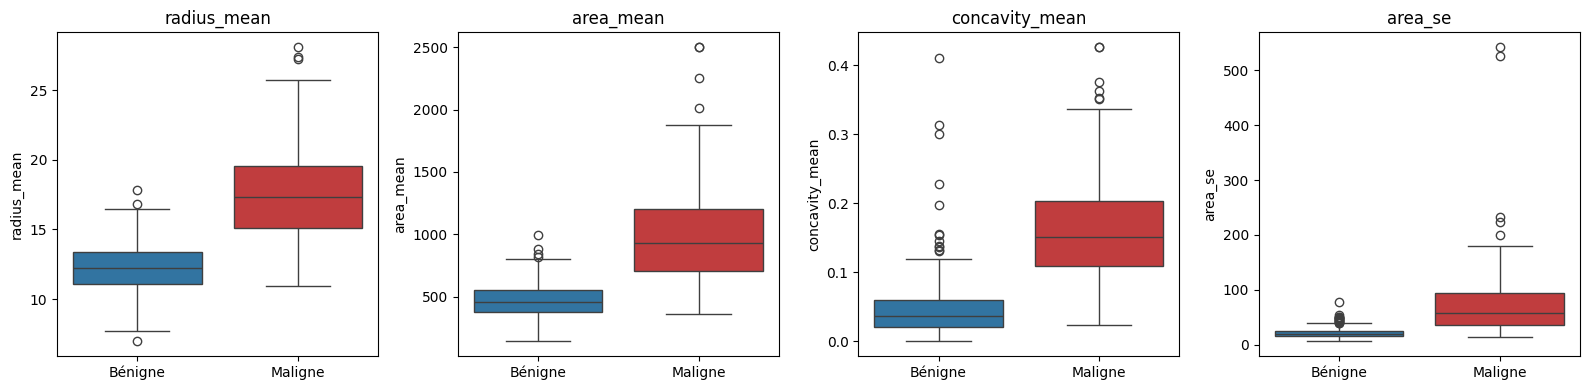

In [13]:
cols_box = ["radius_mean", "area_mean", "concavity_mean", "area_se"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, cols_box):
    sns.boxplot(data=df, x="target", y=col, ax=ax, hue="target",
                palette={0: "tab:blue", 1: "tab:red"}, legend=False)
    ax.set_xticks([0, 1], ["Bénigne", "Maligne"])
    ax.set_xlabel("")
    ax.set_title(col)
plt.tight_layout()
plt.show()

Avec la méthode de l'écart interquartile, 171 lignes ont au moins une valeur "aberrante", et une grosse partie de ces lignes sont des tumeurs malignes. Sur les boxplots, les valeurs extrêmes sont surtout du côté malin : ce sont de très grosses cellules ou des contours très irréguliers.

J'ai décidé de **garder ces valeurs**. Ce ne sont pas des erreurs de saisie, ce sont de vraies mesures, et elles correspondent justement aux cas de cancer les plus marqués. Les supprimer reviendrait à enlever presque un tiers du dataset et une partie importante des tumeurs malignes.

### Corrélations entre les variables

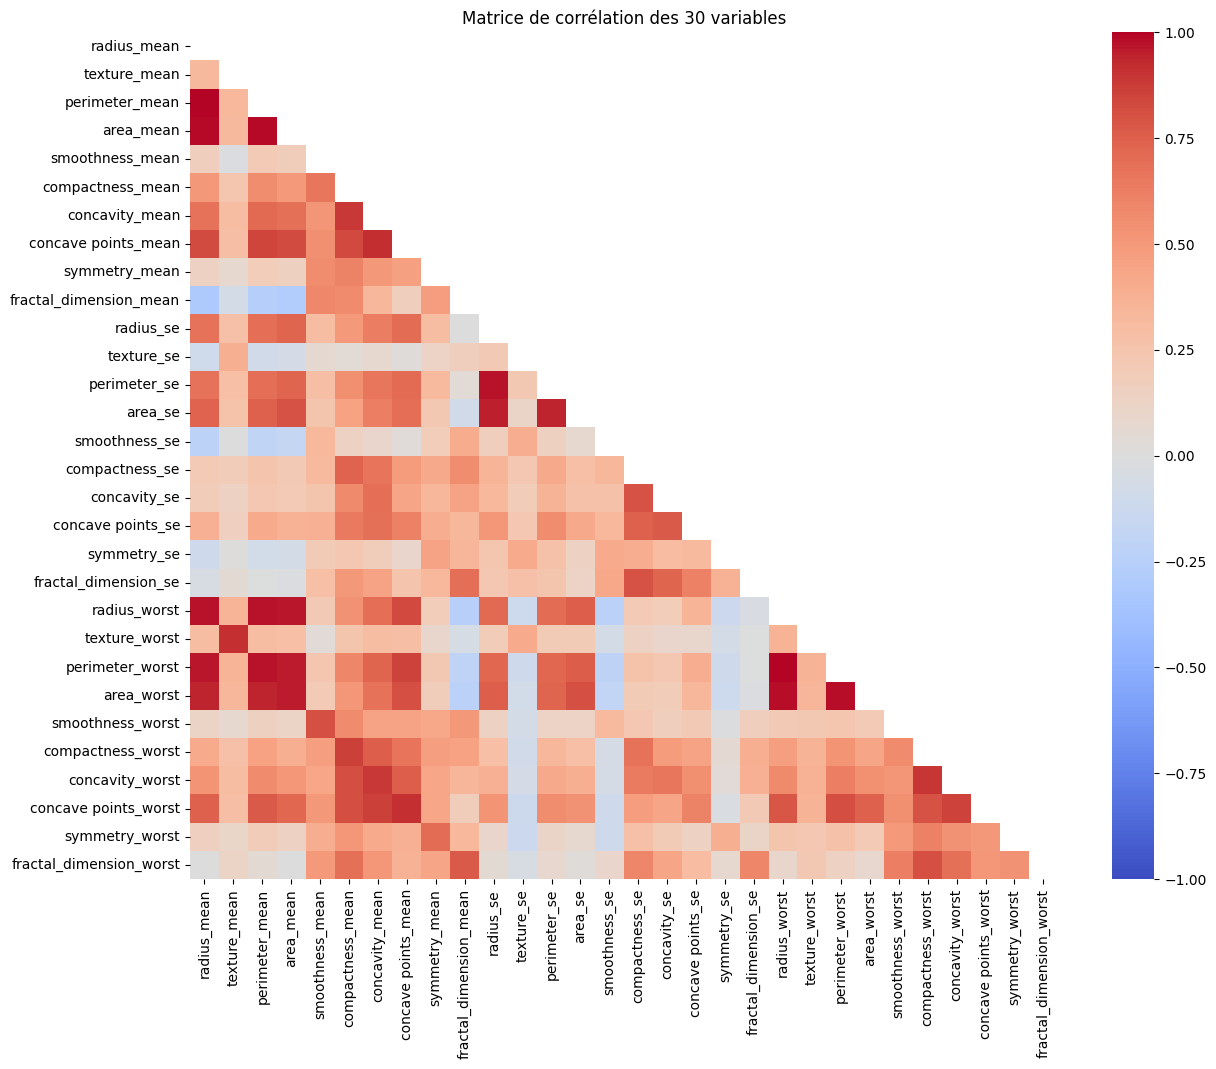

Nombre de paires avec |corrélation| > 0.9 : 21
radius_mean     perimeter_mean     0.997855
radius_worst    perimeter_worst    0.993708
radius_mean     area_mean          0.987357
perimeter_mean  area_mean          0.986507
radius_worst    area_worst         0.984015
dtype: float64


In [14]:
corr = df.drop(columns=["target"]).corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(14, 11))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matrice de corrélation des 30 variables")
plt.show()

paires = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print("Nombre de paires avec |corrélation| > 0.9 :", (paires.abs() > 0.9).sum())
print(paires.sort_values(ascending=False).head(5))

Beaucoup de variables sont très corrélées entre elles. Le cas le plus évident c'est **radius, perimeter et area**, avec des corrélations au-dessus de 0,98. C'est logique : le périmètre et l'aire se calculent à partir du rayon. Les versions `_mean` et `_worst` d'une même mesure sont aussi très corrélées. Au total il y a 21 paires de variables avec une corrélation supérieure à 0,9.

Ça veut dire qu'une bonne partie des 30 colonnes répètent la même information. C'est ce qui justifie de **réduire la dimension** avant de modéliser.

### Corrélation avec le diagnostic

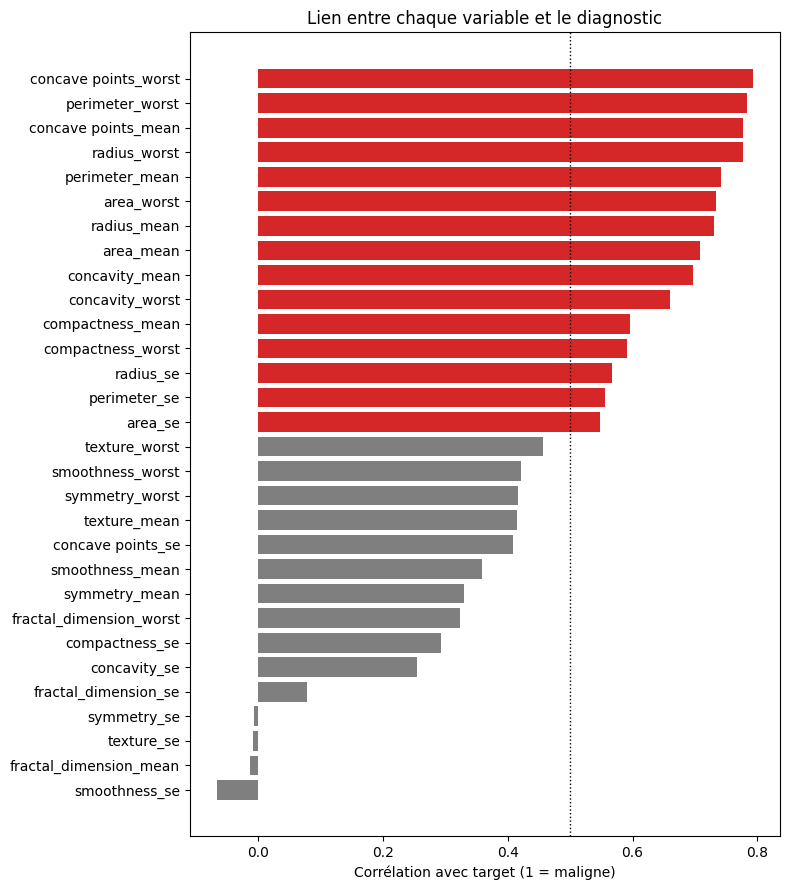

In [15]:
corr_target = df.corr()["target"].drop("target").sort_values()

plt.figure(figsize=(8, 9))
plt.barh(corr_target.index, corr_target.values,
         color=["tab:red" if v > 0.5 else "tab:gray" for v in corr_target.values])
plt.axvline(0.5, color="black", linestyle=":", linewidth=1)
plt.xlabel("Corrélation avec target (1 = maligne)")
plt.title("Lien entre chaque variable et le diagnostic")
plt.tight_layout()
plt.show()

Les variables les plus liées au diagnostic sont `concave points_worst`, `perimeter_worst`, `concave points_mean` et `radius_worst` (autour de 0,78). Ça confirme ce qu'on voyait sur les histogrammes : la **taille** des noyaux et l'**irrégularité de leur contour** sont les deux signes principaux d'une tumeur maligne. Quelques variables comme `texture_se`, `symmetry_se` ou `fractal_dimension_mean` n'ont quasiment aucun lien avec le diagnostic.

### Ce que je retiens de l'analyse exploratoire

- Les données sont propres (pas de valeurs manquantes ni de doublons).
- Les classes sont un peu déséquilibrées (63 / 37), donc je regarderai le rappel et pas seulement l'accuracy.
- Les échelles sont très différentes, il faut standardiser.
- Beaucoup de variables sont redondantes, il faut réduire la dimension.
- Plusieurs variables séparent déjà bien les deux classes, donc un modèle linéaire comme le perceptron a des chances de bien marcher.

## 6. Réduction de dimension (ACP)

### Séparation train / test

Avant de transformer les données, je sépare un jeu d'entraînement (80 %) et un jeu de test (20 %). J'utilise `stratify=y` pour garder la même proportion de tumeurs malignes dans les deux jeux. Il faut faire la séparation **avant** la standardisation et l'ACP : sinon le modèle "verrait" déjà des informations sur les données de test pendant l'entraînement.

In [16]:
X = df.drop(columns=["target"]).values
y = df["target"].values
feature_names = df.drop(columns=["target"]).columns

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train :", X_train.shape, "| Test :", X_test.shape)

Train : (455, 30) | Test : (114, 30)


### Standardisation

Le `StandardScaler` met chaque variable à une moyenne de 0 et un écart-type de 1. Il est entraîné (`fit`) uniquement sur le train, puis appliqué (`transform`) sur le test.

In [17]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

### Pourquoi l'ACP ?

J'ai choisi l'**Analyse en Composantes Principales** (ACP, ou PCA en anglais). Elle crée de nouvelles variables, les composantes principales, qui sont des combinaisons des variables de départ et qui ne sont pas corrélées entre elles. C'est adapté à notre cas puisque l'analyse exploratoire a montré beaucoup de redondance. En plus, l'ACP est une transformation linéaire, ce qui va bien avec un modèle linéaire comme le perceptron.

J'ai aussi regardé d'autres méthodes. t-SNE et UMAP sont surtout faits pour visualiser et ne permettent pas facilement de transformer de nouvelles données de test de la même façon. Boruta (dans la base de connaissances du sujet) fait de la sélection de variables : il garde certaines colonnes d'origine, ce qui est plus facile à interpréter, mais il ne règle pas le problème des variables très corrélées entre elles.

### Combien de composantes garder ?

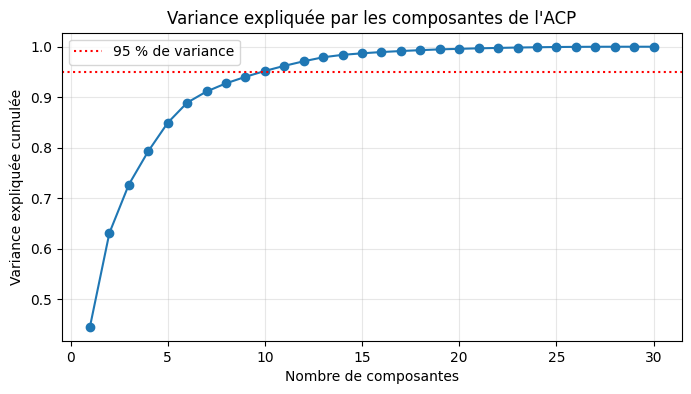

1 composante(s) : 44.6% de la variance
2 composante(s) : 63.1% de la variance
3 composante(s) : 72.7% de la variance
5 composante(s) : 84.9% de la variance
10 composante(s) : 95.2% de la variance


In [18]:
pca_full = PCA().fit(X_train_s)
variance_cumulee = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 31), variance_cumulee, marker="o")
plt.axhline(0.95, color="red", linestyle=":", label="95 % de variance")
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance expliquée cumulée")
plt.title("Variance expliquée par les composantes de l'ACP")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

for k in [1, 2, 3, 5, 10]:
    print(f"{k} composante(s) : {variance_cumulee[k-1]:.1%} de la variance")

La première composante explique déjà 45 % de l'information et les deux premières 63 %. Il faut **10 composantes pour garder 95 %** de la variance. J'ai choisi ce seuil de 95 % parce qu'il permet de diviser le nombre de variables par 3 tout en perdant très peu d'information.

In [19]:
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_s)
X_test_pca = pca.transform(X_test_s)

print("Nombre de composantes :", pca.n_components_)
print("Variance conservée :", round(pca.explained_variance_ratio_.sum(), 4))

Nombre de composantes : 10
Variance conservée : 0.9521


### Visualisation sur les deux premières composantes

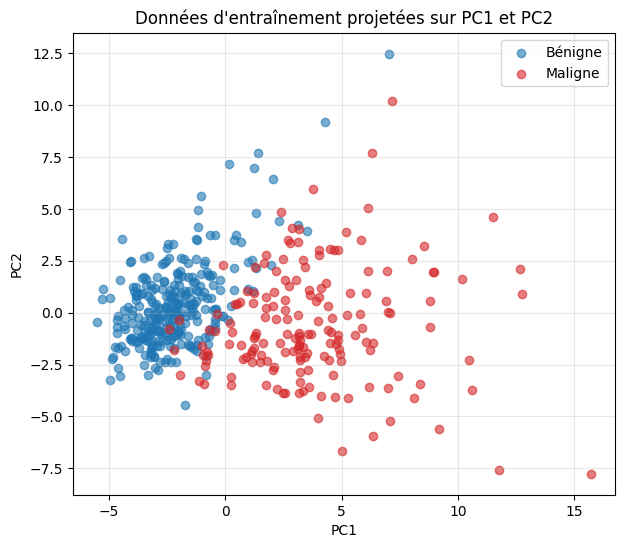

In [20]:
plt.figure(figsize=(7, 6))
plt.scatter(X_train_pca[y_train == 0, 0], X_train_pca[y_train == 0, 1], c="tab:blue", alpha=0.6, label="Bénigne")
plt.scatter(X_train_pca[y_train == 1, 0], X_train_pca[y_train == 1, 1], c="tab:red", alpha=0.6, label="Maligne")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Données d'entraînement projetées sur PC1 et PC2")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Rien qu'avec les deux premières composantes, les tumeurs bénignes (à gauche) et malignes (à droite) sont déjà assez bien séparées. Il y a quand même une zone au milieu où les deux classes se mélangent : les données ne sont donc probablement pas parfaitement séparables par une droite.

### Cercle des corrélations

Pour comprendre ce que représentent les composantes, je trace le cercle des corrélations : chaque flèche est une variable de départ. Plus elle est proche du cercle, mieux elle est représentée par PC1 et PC2, et sa direction montre avec quelle composante elle est corrélée.

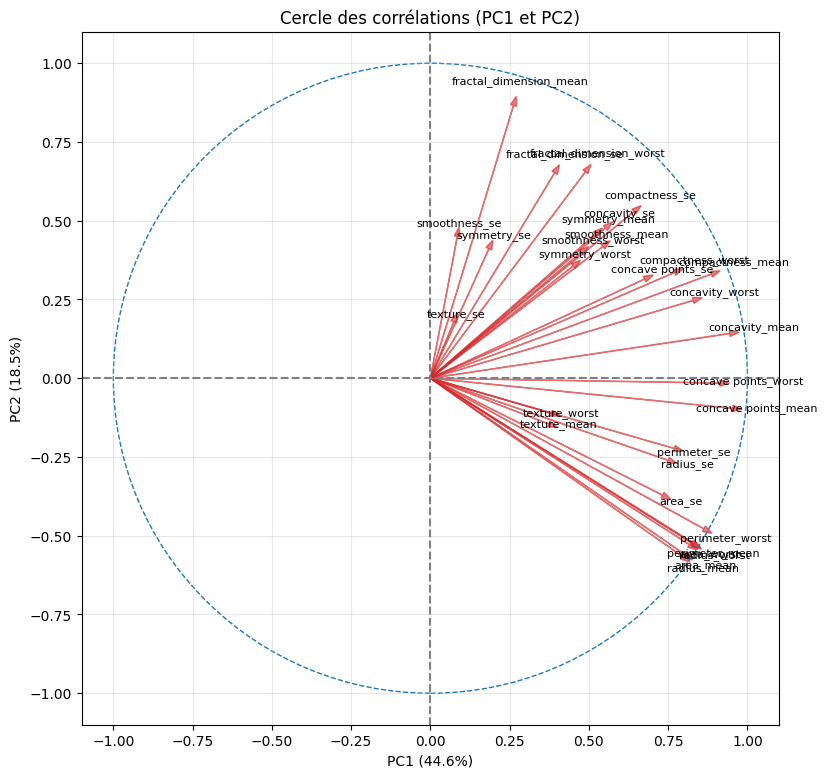

In [21]:
def plot_correlation_circle(pca, feature_names):
    # corrélation entre chaque variable et les deux premières composantes
    corr_pc = pca.components_[:2].T * np.sqrt(pca.explained_variance_[:2])

    plt.figure(figsize=(9, 9))
    for i, (x, y_) in enumerate(corr_pc):
        plt.arrow(0, 0, x, y_, head_width=0.02, color="tab:red", alpha=0.6)
        plt.text(x * 1.08, y_ * 1.08, feature_names[i], fontsize=8, ha="center")

    cercle = plt.Circle((0, 0), 1, fill=False, linestyle="--", color="tab:blue")
    plt.gca().add_artist(cercle)
    plt.axhline(0, color="grey", linestyle="--")
    plt.axvline(0, color="grey", linestyle="--")
    plt.xlim(-1.1, 1.1)
    plt.ylim(-1.1, 1.1)
    plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
    plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
    plt.title("Cercle des corrélations (PC1 et PC2)")
    plt.grid(alpha=0.3)
    plt.show()

plot_correlation_circle(pca, feature_names)

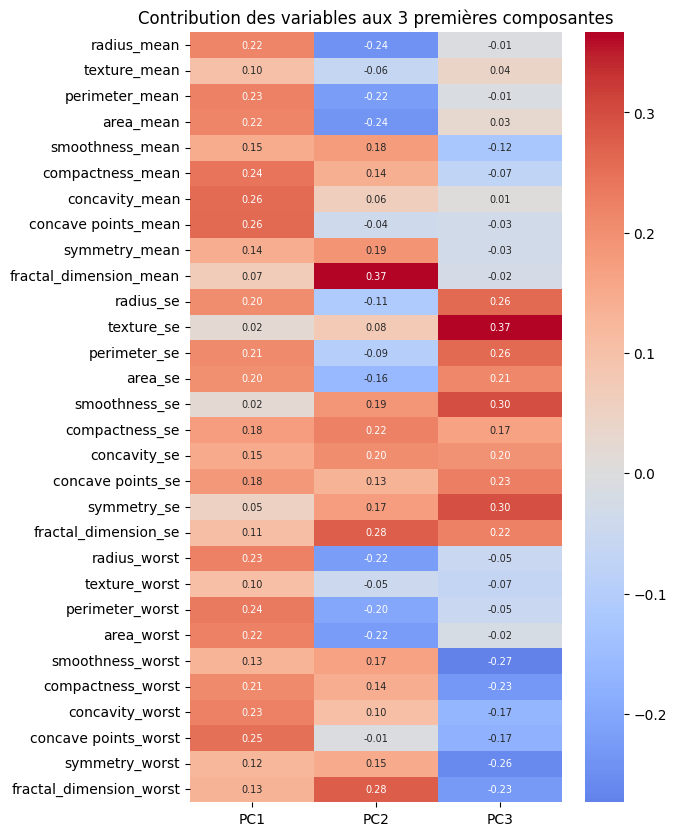

In [22]:
loadings = pd.DataFrame(pca.components_[:3].T, index=feature_names, columns=["PC1", "PC2", "PC3"])

plt.figure(figsize=(6, 10))
sns.heatmap(loadings, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Contribution des variables aux 3 premières composantes")
plt.show()

Comment j'interprète les trois premières composantes :

- **PC1** : toutes les variables y contribuent positivement, surtout `concave points`, `concavity` et `compactness`. C'est un axe "taille et irrégularité générale" de la cellule. Plus PC1 est grand, plus la cellule est grosse et déformée. C'est pour ça que les tumeurs malignes sont à droite sur le graphique.
- **PC2** : elle oppose la taille (`radius`, `area` en négatif) à la `fractal_dimension` et la `compactness` (en positif). Elle distingue les petites cellules au contour compliqué des grosses cellules plus régulières.
- **PC3** : elle est surtout portée par les erreurs standard (`texture_se`, `smoothness_se`, `symmetry_se`). Elle représente la variabilité des mesures à l'intérieur d'une même tumeur.

Les composantes suivantes expliquent chacune moins de 6 % de la variance et sont plus difficiles à interpréter.

## 7. Modélisation avec mon perceptron

### Entraînement

J'entraîne mon perceptron sur les 10 composantes de l'ACP, avec 200 époques.

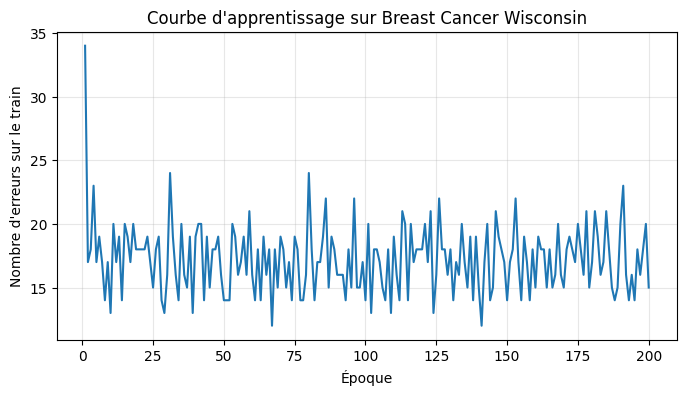

Erreurs sur les 10 dernières époques : [23, 16, 14, 16, 14, 18, 16, 18, 20, 15]


In [23]:
model = Perceptron(learning_rate=0.01, n_epochs=200)
model.fit(X_train_pca, y_train)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(model.errors_) + 1), model.errors_)
plt.xlabel("Époque")
plt.ylabel("Nombre d'erreurs sur le train")
plt.title("Courbe d'apprentissage sur Breast Cancer Wisconsin")
plt.grid(alpha=0.3)
plt.show()

print("Erreurs sur les 10 dernières époques :", model.errors_[-10:])

Le nombre d'erreurs baisse très vite pendant les premières époques, puis il reste bloqué entre environ 10 et 25 erreurs par époque, sans jamais arriver à 0. Contrairement aux données aléatoires de la partie 3, les deux classes ne sont pas parfaitement séparables par un hyperplan : quelques tumeurs se trouvent au milieu de l'autre classe. Le perceptron continue donc de corriger ses poids à l'infini, et le modèle final correspond juste aux poids de la dernière époque.

### Évaluation sur le jeu de test

J'utilise plusieurs métriques :

- **Accuracy** : la proportion de bonnes prédictions.
- **Précision** : parmi les tumeurs prédites malignes, combien le sont vraiment.
- **Rappel (sensibilité)** : parmi les vraies tumeurs malignes, combien ont été détectées. C'est la métrique la plus importante ici, parce qu'un cancer non détecté (faux négatif) peut avoir des conséquences graves.
- **Spécificité** : parmi les tumeurs bénignes, combien ont bien été reconnues comme bénignes.
- **F1-score** : un compromis entre la précision et le rappel.

In [24]:
y_pred = model.predict(X_test_pca)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

print(f"Accuracy    : {accuracy_score(y_test, y_pred):.3f}")
print(f"Précision   : {precision_score(y_test, y_pred):.3f}")
print(f"Rappel      : {recall_score(y_test, y_pred):.3f}")
print(f"Spécificité : {tn / (tn + fp):.3f}")
print(f"F1-score    : {f1_score(y_test, y_pred):.3f}")

Accuracy    : 0.965
Précision   : 0.932
Rappel      : 0.976
Spécificité : 0.958
F1-score    : 0.953


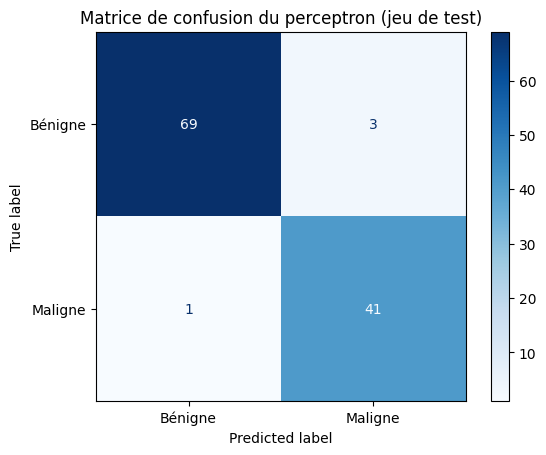

In [25]:
disp = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Bénigne", "Maligne"])
disp.plot(values_format="d", cmap="Blues")
plt.title("Matrice de confusion du perceptron (jeu de test)")
plt.show()

Sur les 114 tumeurs du jeu de test, le perceptron se trompe 4 fois (96,5 % d'accuracy) :

- **1 faux négatif** : une tumeur maligne classée bénigne. Le rappel est donc de 97,6 % (41 cancers détectés sur 42). C'est l'erreur la plus grave, parce que la patiente ne serait pas traitée.
- **3 faux positifs** : des tumeurs bénignes classées malignes. La précision est de 93,2 %. Ces erreurs sont moins graves : elles entraîneraient des examens supplémentaires et beaucoup de stress, mais pas un cancer oublié.


L'AUC est d'environ 0,99. Ça veut dire que dans presque tous les cas, une tumeur maligne obtient un score $z$ plus élevé qu'une tumeur bénigne. La courbe montre aussi qu'en déplaçant le seuil (au lieu de garder $z \geq 0$), on pourrait détecter tous les cancers en acceptant un peu plus de faux positifs.

### Vérification avec le perceptron de scikit-learn

Pour m'assurer que mon implémentation est correcte, je compare avec la classe `Perceptron` de scikit-learn sur exactement les mêmes données.

In [27]:
from sklearn.linear_model import Perceptron as SkPerceptron

sk_model = SkPerceptron(random_state=42)
sk_model.fit(X_train_pca, y_train)
y_pred_sk = sk_model.predict(X_test_pca)

comparaison = pd.DataFrame({
    "Mon perceptron": [accuracy_score(y_test, y_pred), recall_score(y_test, y_pred), precision_score(y_test, y_pred)],
    "Perceptron sklearn": [accuracy_score(y_test, y_pred_sk), recall_score(y_test, y_pred_sk), precision_score(y_test, y_pred_sk)],
}, index=["Accuracy", "Rappel", "Précision"])
comparaison.round(3)

,Mon perceptron,Perceptron sklearn
Accuracy,0.965,0.965
Rappel,0.976,0.952
Précision,0.932,0.952


Les résultats sont très proches. Mon perceptron se trompe sur le même nombre de tumeurs (4) que celui de scikit-learn, avec un faux négatif en moins. Les petites différences viennent du fait que scikit-learn mélange les données à chaque époque et s'arrête automatiquement. Ça confirme que ma classe fonctionne correctement.

### Est-ce que l'ACP a servi ?

Je compare avec le même perceptron entraîné sur les 30 variables standardisées, sans réduction de dimension.

In [28]:
model_30 = Perceptron(learning_rate=0.01, n_epochs=200)
model_30.fit(X_train_s, y_train)
y_pred_30 = model_30.predict(X_test_s)

print(f"30 variables : accuracy = {accuracy_score(y_test, y_pred_30):.3f} | rappel = {recall_score(y_test, y_pred_30):.3f}")
print(f"ACP (10 comp.) : accuracy = {accuracy_score(y_test, y_pred):.3f} | rappel = {recall_score(y_test, y_pred):.3f}")

30 variables : accuracy = 0.939 | rappel = 0.881
ACP (10 comp.) : accuracy = 0.965 | rappel = 0.976


Sur ce découpage, le modèle avec l'ACP est meilleur, surtout pour le rappel (97,6 % contre 88,1 %). Avec 30 variables très corrélées, le perceptron rate plus de cancers. Mais avec seulement 114 tumeurs dans le test, une seule erreur fait varier le rappel de plus de 2 points. Je vérifie donc la stabilité des résultats avec une validation croisée.

### Validation croisée

Je découpe les données en 5 parties. Chaque partie sert une fois de jeu de test pendant que le modèle est entraîné sur les 4 autres. À chaque fois, le scaler et l'ACP sont ré-entraînés uniquement sur la partie d'entraînement.

In [29]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultats = []

for train_idx, test_idx in skf.split(X, y):
    sc = StandardScaler().fit(X[train_idx])
    acp = PCA(n_components=0.95).fit(sc.transform(X[train_idx]))
    Xtr = acp.transform(sc.transform(X[train_idx]))
    Xte = acp.transform(sc.transform(X[test_idx]))

    p = Perceptron(learning_rate=0.01, n_epochs=200).fit(Xtr, y[train_idx])
    pred = p.predict(Xte)
    resultats.append({
        "accuracy": accuracy_score(y[test_idx], pred),
        "precision": precision_score(y[test_idx], pred),
        "rappel": recall_score(y[test_idx], pred),
        "f1": f1_score(y[test_idx], pred),
    })

resultats = pd.DataFrame(resultats)
print(resultats.round(3))
print("\nMoyenne :")
print(resultats.agg(["mean", "std"]).round(3))

   accuracy  precision  rappel     f1
0     0.982      1.000   0.953  0.976
1     0.956      0.975   0.907  0.940
2     0.939      0.973   0.857  0.911
3     0.974      0.933   1.000  0.966
4     0.982      1.000   0.952  0.976

Moyenne :
      accuracy  precision  rappel     f1
mean     0.967      0.976   0.934  0.954
std      0.019      0.027   0.054  0.028


En moyenne sur les 5 découpages, on obtient 96,7 % d'accuracy et 93,4 % de rappel. L'accuracy reste stable, ce qui montre que le résultat du premier test n'est pas un coup de chance. Par contre le rappel varie beaucoup d'un découpage à l'autre (de 85,7 % à 100 %) : selon les données, le perceptron rate entre 0 et 6 cancers. Le 97,6 % du premier test était plutôt un découpage favorable.

### Influence du nombre d'époques

Comme le perceptron ne converge pas sur ces données, je regarde si le nombre d'époques change le résultat.

In [30]:
lignes = []
for n_ep in [10, 50, 100, 200, 500]:
    p = Perceptron(learning_rate=0.01, n_epochs=n_ep).fit(X_train_pca, y_train)
    pred = p.predict(X_test_pca)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pred).ravel()
    lignes.append({"époques": n_ep, "accuracy": accuracy_score(y_test, pred),
                   "rappel": recall_score(y_test, pred), "faux négatifs": fn_, "faux positifs": fp_})

pd.DataFrame(lignes).round(3)

,époques,accuracy,rappel,faux négatifs,faux positifs
0,10,0.974,0.952,2,1
1,50,0.974,0.952,2,1
2,100,0.974,0.976,1,2
3,200,0.965,0.976,1,3
4,500,0.956,0.905,4,1


Les résultats changent avec le nombre d'époques, et ils ne s'améliorent pas quand on entraîne plus longtemps : avec 500 époques, le modèle rate 4 cancers au lieu de 1 avec 200 époques. C'est une conséquence directe de la non-convergence : les poids oscillent, et le modèle final dépend de l'endroit où on s'arrête. C'est un vrai problème pour un usage médical, parce que le modèle n'est pas stable.

### Frontière de décision en 2D

Pour visualiser ce que fait le perceptron, je l'entraîne sur seulement 2 composantes de l'ACP et j'utilise la méthode `plot` de ma classe.

Avec 2 composantes : accuracy = 0.939 | rappel = 0.857


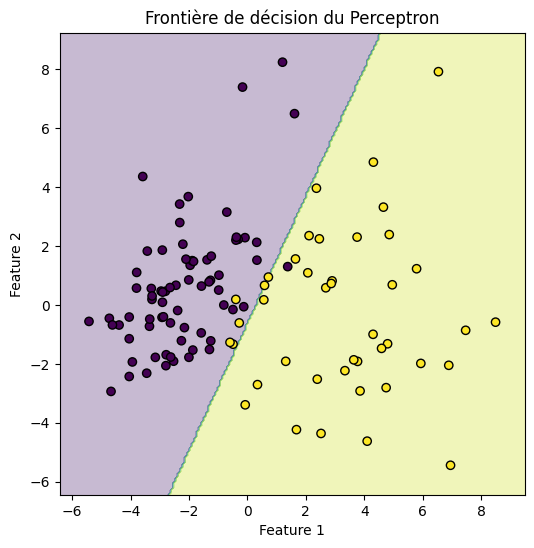

In [31]:
pca2 = PCA(n_components=2, random_state=42)
X_train_2d = pca2.fit_transform(X_train_s)
X_test_2d = pca2.transform(X_test_s)

model_2d = Perceptron(learning_rate=0.01, n_epochs=200).fit(X_train_2d, y_train)
y_pred_2d = model_2d.predict(X_test_2d)
print(f"Avec 2 composantes : accuracy = {accuracy_score(y_test, y_pred_2d):.3f} | rappel = {recall_score(y_test, y_pred_2d):.3f}")

model_2d.plot(X_test_2d, y_test)

La frontière est une simple droite. Elle sépare bien la grande majorité des tumeurs, mais quelques points sont du mauvais côté, surtout dans la zone où les deux classes se mélangent. Avec seulement 2 composantes, le rappel baisse à environ 86 % : on perd de l'information, c'est pour ça que j'ai gardé 10 composantes pour le vrai modèle.

## 8. Conclusion

### Efficacité du perceptron sur ce problème

Le perceptron donne des résultats plutôt bons sur le dataset Breast Cancer Wisconsin : environ 96 à 97 % d'accuracy, une AUC proche de 0,99 et un rappel moyen de 93 % en validation croisée. C'est cohérent avec l'analyse exploratoire : la taille et l'irrégularité des noyaux séparent déjà bien les tumeurs bénignes et malignes, donc une frontière linéaire marche bien. La standardisation et l'ACP ont aussi aidé, en supprimant la redondance entre les variables.

Mais pour un problème médical, ce n'est pas suffisant :

- Le modèle rate encore des cancers : en moyenne 7 % des tumeurs malignes ne sont pas détectées, et le rappel change beaucoup selon le découpage des données.
- Les données ne sont pas parfaitement séparables, donc l'apprentissage ne converge jamais. Le résultat dépend du nombre d'époques et de l'ordre des données, et le modèle n'est pas stable.
- Il répond seulement 0 ou 1. Un médecin aurait besoin d'un niveau de confiance pour savoir quels cas vérifier en priorité.
- Après l'ACP, les variables ne correspondent plus directement à des mesures médicales, donc c'est plus difficile d'expliquer une décision.

Le perceptron est donc un bon point de départ pour comprendre le fonctionnement d'un neurone artificiel, mais je ne l'utiliserais pas tel quel comme outil d'aide au diagnostic.

### Pistes d'amélioration (non implémentées)

- **Algorithme "pocket"** : garder en mémoire les poids qui ont fait le moins d'erreurs pendant l'entraînement, au lieu de garder ceux de la dernière époque. Ça réglerait le problème d'instabilité.
- **Mélanger les données à chaque époque et arrêter l'entraînement automatiquement** quand le nombre d'erreurs ne baisse plus.
- **Régression logistique** : c'est presque le même modèle, mais avec une sigmoïde au lieu de la fonction seuil. Elle donne une probabilité et converge même si les données ne sont pas séparables.
- **Ajuster le seuil de décision** pour favoriser le rappel : accepter un peu plus de faux positifs pour ne rater aucun cancer. La courbe ROC montre que c'est possible.
- **Pondérer les classes**, pour que se tromper sur une tumeur maligne coûte plus cher pendant l'apprentissage.
- **Tester d'autres modèles** : SVM, forêts aléatoires, ou un perceptron multicouche (MLP) capable d'apprendre des frontières non linéaires.
- **Sélectionner les variables avec Boruta** au lieu de l'ACP, pour garder des variables médicales compréhensibles.
- **Optimiser les hyperparamètres** (nombre d'époques, nombre de composantes) avec une validation croisée, et si possible tester sur des données d'autres hôpitaux.